In [ ]:
pip install pandas sqlalchemy pymysql


In [51]:
import os
os.makedirs('/content/Charts', exist_ok=True)

In [ ]:
import pandas as pd
df = pd.read_csv('/content/netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
print("dataset_shape:",df.shape)
print("\ncolumn names:")
print(df.columns.tolist())
print("\n dataset information")
df.info()

dataset_shape: (8807, 12)

column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

 dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
print("Total Records:", len(df))

Total Records: 8807


In [ ]:
df.isnull().sum()


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

missing

,Missing Values,Percentage
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
director,2634,29.908028
cast,825,9.367549
country,831,9.435676
date_added,10,0.113546
release_year,0,0.000000
rating,4,0.045418
duration,3,0.034064


In [ ]:
print("Total Duplicates:", df.duplicated().sum())

Total Duplicates: 0


In [ ]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


In [ ]:
df.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [13]:
print("Total Duplicates:", df.duplicated().sum())
df.dtypes


Total Duplicates: 0


,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


In [15]:
df[df['duration'].isnull()]
df[df['rating'].isnull()]
df[df['date_added'].isnull()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,NaN,Anthony Bourdain,United States,NaN,2018,TV-PG,5 Seasons,Docuseries,This CNN original series has chef Anthony Bour...
6795,s6796,TV Show,Frasier,NaN,"Kelsey Grammer, Jane Leeves, David Hyde Pierce...",United States,NaN,2003,TV-PG,11 Seasons,"Classic & Cult TV, TV Comedies",Frasier Crane is a snooty but lovable Seattle ...
6806,s6807,TV Show,Friends,NaN,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaN,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...
6901,s6902,TV Show,Gunslinger Girl,NaN,"Yuuka Nanri, Kanako Mitsuhashi, Eri Sendai, Am...",Japan,NaN,2008,TV-14,2 Seasons,"Anime Series, Crime TV Shows","On the surface, the Social Welfare Agency appe..."
7196,s7197,TV Show,Kikoriki,NaN,Igor Dmitriev,NaN,NaN,2010,TV-Y,2 Seasons,Kids' TV,A wacky rabbit and his gang of animal pals hav...
7254,s7255,TV Show,La Familia P. Luche,NaN,"Eugenio Derbez, Consuelo Duval, Luis Manuel Áv...",United States,NaN,2012,TV-14,3 Seasons,"International TV Shows, Spanish-Language TV Sh...","This irreverent sitcom featues Ludovico, Feder..."
7406,s7407,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
7847,s7848,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
8182,s8183,TV Show,The Adventures of Figaro Pho,NaN,"Luke Jurevicius, Craig Behenna, Charlotte Haml...",Australia,NaN,2015,TV-Y7,2 Seasons,"Kids' TV, TV Comedies","Imagine your worst fears, then multiply them: ..."


In [16]:
df_clean = df.copy()

print("Original Shape:", df.shape)
print("Cleaning DataFrame Shape:", df_clean.shape)

Original Shape: (8807, 12)
Cleaning DataFrame Shape: (8807, 12)


In [18]:
df_clean['director'] = df_clean['director'].fillna('Unknown')

df_clean['cast'] = df_clean['cast'].fillna('Unknown')

df_clean['country'] = df_clean['country'].fillna('Unknown')

df_clean['rating'] = df_clean['rating'].fillna('Unknown')

df_clean['duration'] = df_clean['duration'].fillna('Unknown')

In [19]:
df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'].str.strip(),
    errors='coerce'
)


In [20]:
df_clean.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,0


In [21]:
print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))

print("\nCleaned Dataset Information:")
df_clean.info()

Original Records: 8807
Cleaned Records: 8807

Cleaned Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   object        
 2   title         8807 non-null   object        
 3   director      8807 non-null   object        
 4   cast          8807 non-null   object        
 5   country       8807 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   object        
 9   duration      8807 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 825.8+ KB


In [22]:
print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 0


In [23]:
df_clean.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,datetime64[ns]
release_year,int64
rating,object
duration,object


In [24]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

df_clean.head()

Original Shape: (8807, 12)
Cleaned Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [25]:
print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 0


In [26]:
df_clean.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,0


In [27]:
df_clean['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [28]:
df_clean['type'].value_counts(normalize=True) * 100

,proportion
type,
Movie,69.615079
TV Show,30.384921


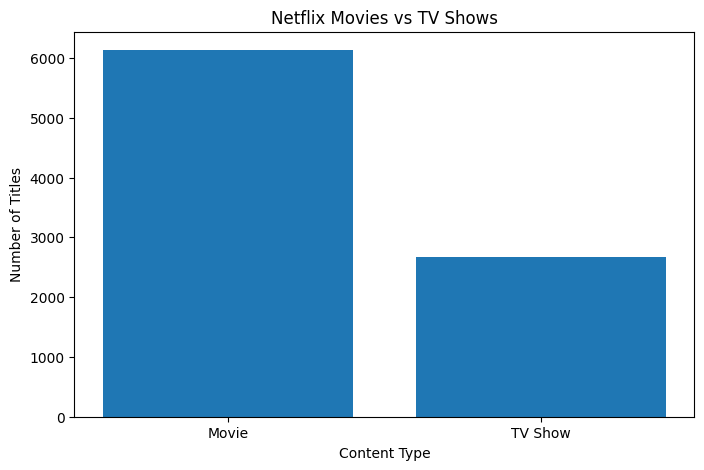

In [52]:
import matplotlib.pyplot as plt

content_counts = df_clean['type'].value_counts()

plt.figure(figsize=(8,5))

plt.bar(content_counts.index, content_counts.values)

plt.title('Netflix Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.savefig('/content/Charts/01_content_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [30]:
df_clean['country'].value_counts().head(10)

,count
country,
United States,2818
India,972
Unknown,831
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124


In [31]:
country_df = df_clean.dropna(subset=['country']).copy()

country_df['country'] = country_df['country'].str.split(',')

country_df = country_df.explode('country')

country_df['country'] = country_df['country'].str.strip()

In [32]:
top_countries = country_df['country'].value_counts().head(10)

print(top_countries)

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


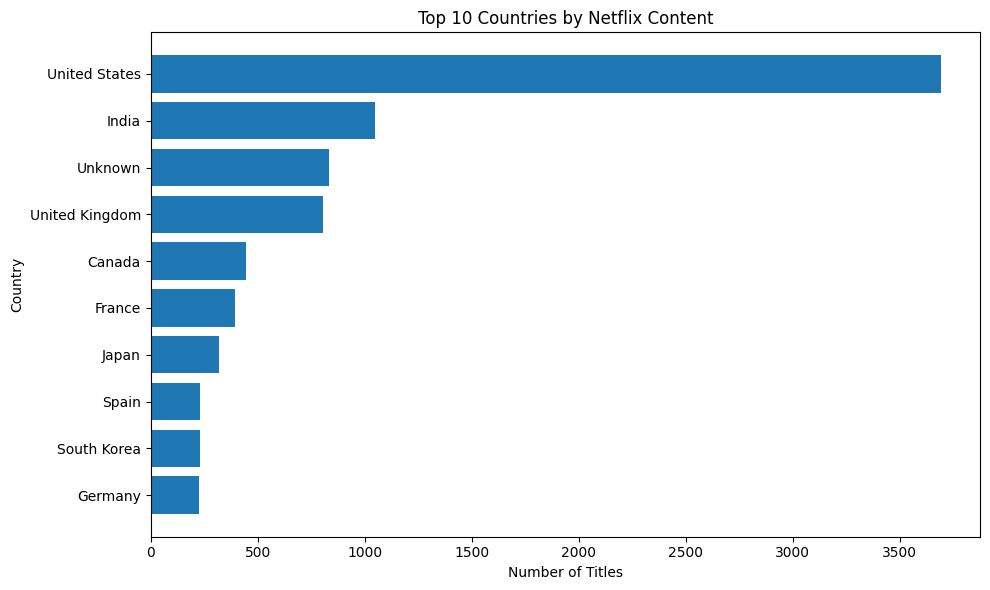

In [53]:
plt.figure(figsize=(10,6))

plt.barh(top_countries.index[::-1], top_countries.values[::-1])

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.tight_layout()
plt.savefig('/content/Charts/02_top_countries.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [34]:
df_clean['date_added_year'] = df_clean['date_added'].dt.year

In [35]:
yearly_content = df_clean['date_added_year'].value_counts().sort_index()

print(yearly_content)

date_added_year
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


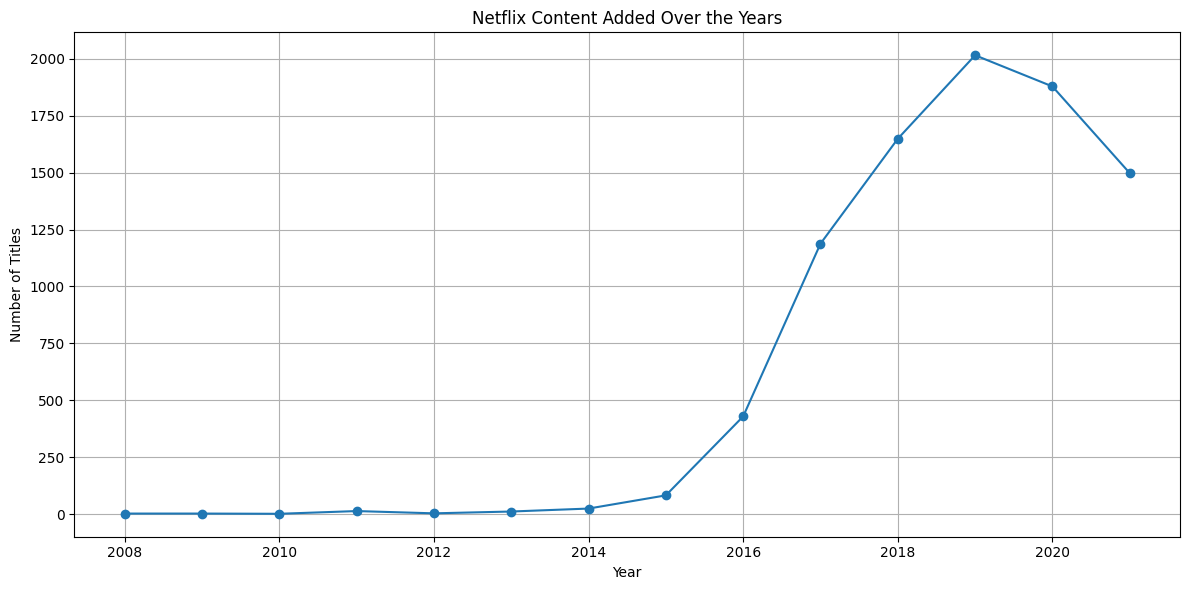

In [54]:
plt.figure(figsize=(12,6))

plt.plot(yearly_content.index, yearly_content.values, marker='o')

plt.title('Netflix Content Added Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Titles')

plt.grid(True)
plt.tight_layout()
plt.savefig('/content/Charts/03_yearly_content_trend.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [37]:
yearly_type = df_clean.groupby(
    ['date_added_year', 'type']
).size().unstack(fill_value=0)

print(yearly_type)

type             Movie  TV Show
date_added_year                
2008.0               1        1
2009.0               2        0
2010.0               1        0
2011.0              13        0
2012.0               3        0
2013.0               6        5
2014.0              19        5
2015.0              56       26
2016.0             253      176
2017.0             839      349
2018.0            1237      412
2019.0            1424      592
2020.0            1284      595
2021.0             993      505


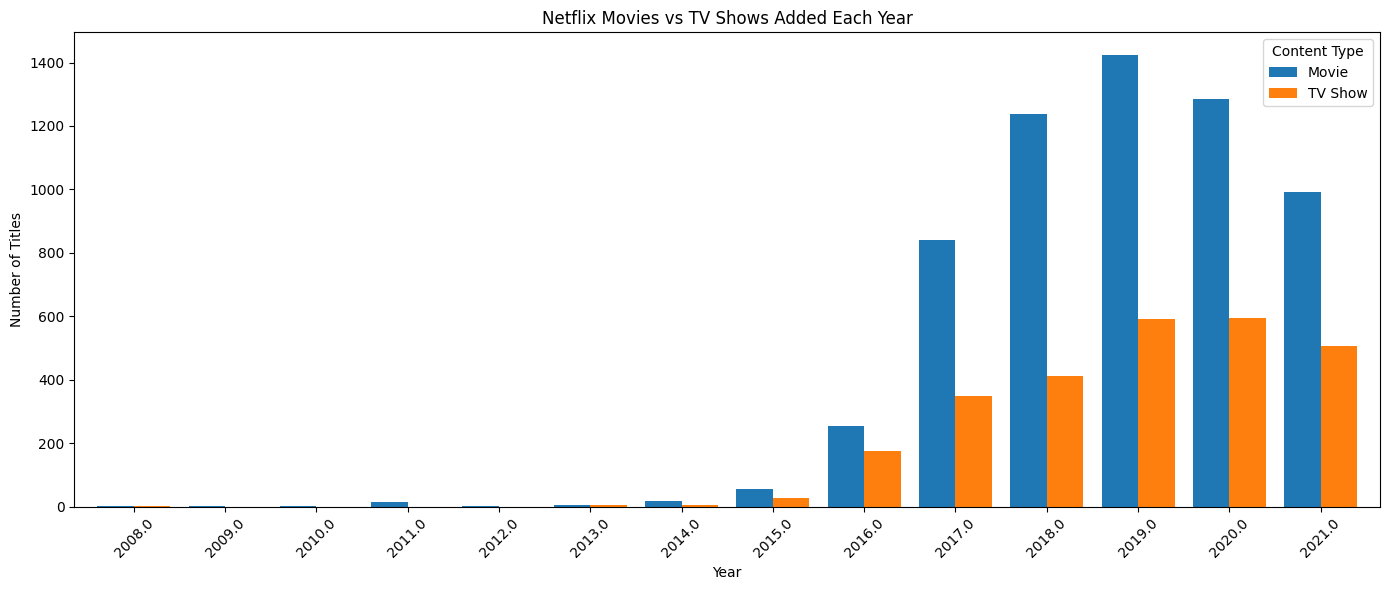

In [55]:
yearly_type.plot(
    kind='bar',
    figsize=(14,6),
    width=0.8
)

plt.title('Netflix Movies vs TV Shows Added Each Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Content Type')
plt.tight_layout()
plt.savefig('/content/Charts/04_movies_vs_tv_yearly.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [39]:
genre_df = df_clean.dropna(subset=['listed_in']).copy()

genre_df['listed_in'] = genre_df['listed_in'].str.split(',')

genre_df = genre_df.explode('listed_in')

genre_df['listed_in'] = genre_df['listed_in'].str.strip()

In [40]:
top_genres = genre_df['listed_in'].value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


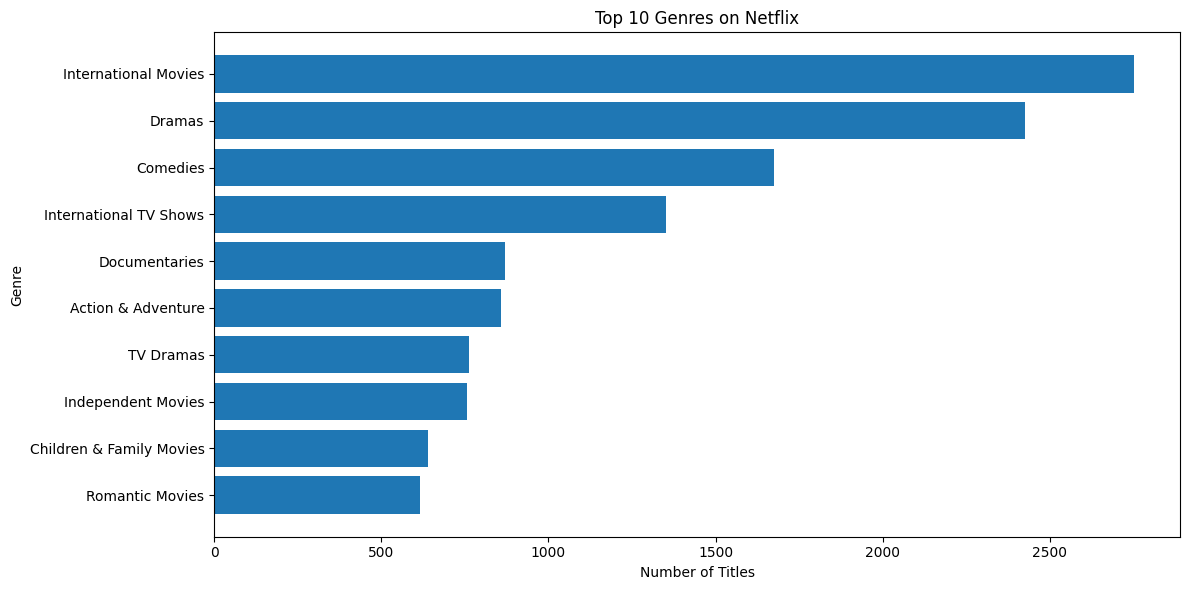

In [56]:
plt.figure(figsize=(12,6))

plt.barh(top_genres.index[::-1], top_genres.values[::-1])

plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.tight_layout()
plt.savefig('/content/Charts/05_top_genres.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [44]:
df_clean['release_period'] = pd.cut(
    df_clean['release_year'],
    bins=[0, 1999, 2009, 2019, 2100],
    labels=['Before 2000', '2000-2009', '2010-2019', '2020 onwards']
)

In [45]:
period_counts = df_clean['release_period'].value_counts().sort_index()

print(period_counts)

release_period
Before 2000      525
2000-2009        810
2010-2019       5927
2020 onwards    1545
Name: count, dtype: int64


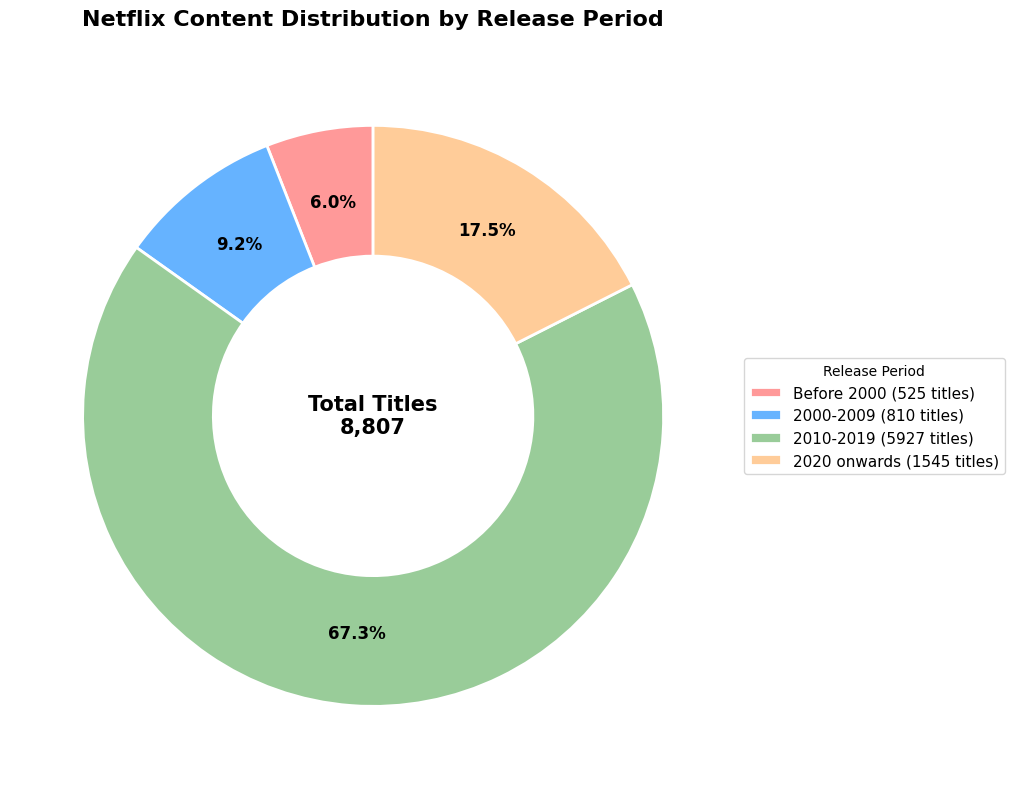

In [57]:
plt.figure(figsize=(11, 8))

total = period_counts.sum()

labels = [
    f'{name} ({count} titles)'
    for name, count in period_counts.items()
]

colors = ['#FF9999', '#66B3FF', '#99CC99', '#FFCC99']

wedges, texts, autotexts = plt.pie(
    period_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    colors=colors,
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.legend(
    wedges,
    labels,
    title='Release Period',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    fontsize=11
)

plt.title(
    'Netflix Content Distribution by Release Period',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.text(
    0, 0,
    f'Total Titles\n{total:,}',
    ha='center',
    va='center',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('/content/Charts/06_release_period_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [49]:
df_clean.to_csv('netflix_cleaned.csv', index=False)

In [50]:
plt.savefig('chart_name.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>